In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
df.shape

(891, 12)

In [3]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [4]:
# Algumas colunas não muito óbvias

# SibSp - Número de irmãos + cônjuge a bordo
# Parch - Número de pais + filhos a bordo
# Ticket - Número do bilhete
# Fare - Valor pago em libras pela passagem
# Cabin - Número da cabine (letra inicial indica o deck)
# Embarked - Porto de embarque (C = Cherbourg; S = Southampton; Q = Queenstown)

# Somando SibSp + Parch + 1 temos o tamanho da família a bordo

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

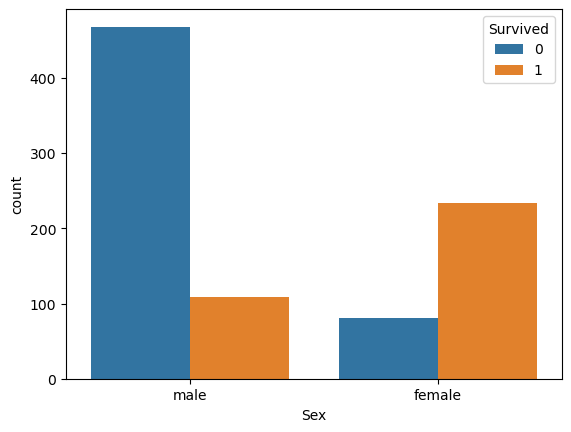

In [9]:
sns.countplot(data=df, x="Sex", hue="Survived")
plt.show()

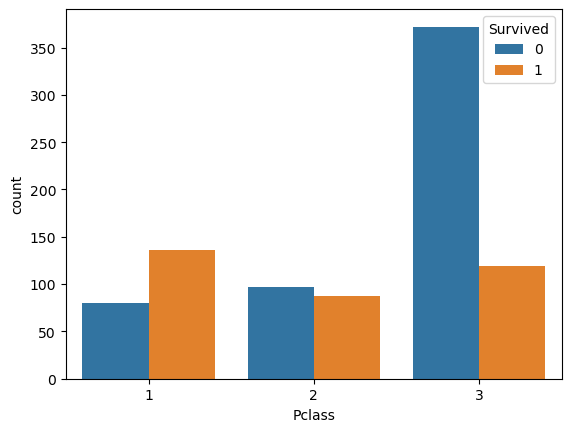

In [10]:
sns.countplot(data=df, x="Pclass", hue="Survived")
plt.show()

### Primeiro Modelo (Versão Mínima)

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [12]:
dados = df[["Survived", "Sex", "Pclass", "Age", "Fare"]].copy()
dados["Age"] = dados["Age"].fillna(dados["Age"].median())
dados["Sex"] = dados["Sex"].map({"male": 0, "female": 1})
dados.head()

,Survived,Sex,Pclass,Age,Fare
0,0,0,3,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,1,3,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,0,3,35.0,8.0500


In [13]:
X = dados.drop("Survived", axis=1)
y = dados["Survived"]

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_treino, y_treino)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [14]:
previsoes = modelo.predict(X_teste)
print("Acurácia:", accuracy_score(y_teste, previsoes))

Acurácia: 0.8044692737430168


In [15]:
modelo.coef_

array([[ 2.46563064e+00, -9.96364826e-01, -2.51645337e-02,
         1.18224793e-03]])

In [16]:
print("Sempre 'morreu':", (y_teste == 0).mean())

regra = (X_teste["Sex"] == 1).astype(int)
print("Regra 'mulher sobrevive':", accuracy_score(y_teste, regra))
print("Seu modelo:", accuracy_score(y_teste, previsoes))

Sempre 'morreu': 0.5865921787709497
Regra 'mulher sobrevive': 0.7821229050279329
Seu modelo: 0.8044692737430168


- Se esse modelo chutar sempre que a pessoa morreu, ele acerta 58,65% dos casos
- Se chutar que sobreviveu sempre que for mulher, acerta 78,21%
- O modelo acertou 80,44%, o que está muito próximo do caso anterior

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [18]:
cm = confusion_matrix(y_teste, previsoes)
print(cm)

[[90 15]
 [20 54]]


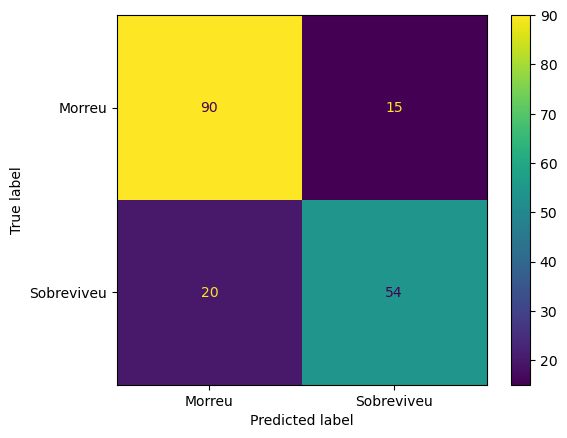

In [19]:
ConfusionMatrixDisplay(cm, display_labels=["Morreu", "Sobreviveu"]).plot()
plt.show()

In [20]:
from sklearn.metrics import classification_report

In [21]:
print(classification_report(y_teste, previsoes, target_names=["Morreu", "Sobreviveu"]))

              precision    recall  f1-score   support

      Morreu       0.82      0.86      0.84       105
  Sobreviveu       0.78      0.73      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.80      0.80      0.80       179



In [22]:
import numpy as np

In [23]:
resultados = []

# Uma forma de validação cruzada, repetindo o teste várias vezes, porém ainda tem a possibilidade de vários passageiros terem sido sorteados mais de uma vez, enquanto outros podem nunca ter sido sorteados.
for seed in range(100):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    m = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
    resultados.append(accuracy_score(y_te, m.predict(X_te)))

print(f"Média: {np.mean(resultados):.3f}")
print(f"Desvio padrão: {np.std(resultados):.3f}")
print(f"Mín: {min(resultados):.3f} | Máx: {max(resultados):.3f}")

Média: 0.789
Desvio padrão: 0.030
Mín: 0.721 | Máx: 0.844


In [24]:
from sklearn.model_selection import cross_val_score

In [25]:
scores = cross_val_score(LogisticRegression(max_iter=1000), X, y, cv=5)
print(scores, scores.mean())

[0.7877095  0.78089888 0.78651685 0.7752809  0.80337079] 0.7867553825874082


In [26]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [27]:
# Validação cruzada de fato, de forma sistemática, garantindo o sorteio de todos os passageiros
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # Stratified mantém a proporção de sobreviventes e mortos em cada "corte"
scores = cross_val_score(LogisticRegression(max_iter=1000), X, y, cv=cv)

print(scores)
print(f"Média: {scores.mean():.3f} | Desvio: {scores.std():.3f}")

[0.81005587 0.80337079 0.78089888 0.76404494 0.78651685]
Média: 0.789 | Desvio: 0.016


In [28]:
dif = []

for seed in range(100):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    m = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
    acc_modelo = accuracy_score(y_te, m.predict(X_te))
    acc_regra = accuracy_score(y_te, (X_te["Sex"] == 1).astype(int))
    dif.append(acc_modelo - acc_regra)

print(f"Diferença média (modelo - regra): {np.mean(dif):.3f}")
print(f"Modelo vence em {sum(d > 0 for d in dif)} de 100 splits")

Diferença média (modelo - regra): 0.001
Modelo vence em 50 de 100 splits


In [29]:
from sklearn.tree import DecisionTreeClassifier

In [30]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

for prof in [1, 2, 3, 5, 10, None]:
    arv = DecisionTreeClassifier(max_depth=prof, random_state=42).fit(X_tr, y_tr)
    print(f"max_depth={prof}: treino={arv.score(X_tr, y_tr):.3f} | teste={arv.score(X_te, y_te):.3f}")

max_depth=1: treino=0.788 | teste=0.782
max_depth=2: treino=0.803 | teste=0.765
max_depth=3: treino=0.827 | teste=0.799
max_depth=5: treino=0.857 | teste=0.804
max_depth=10: treino=0.917 | teste=0.782
max_depth=None: treino=0.978 | teste=0.732


In [31]:
from sklearn.ensemble import RandomForestClassifier

In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "Logística": LogisticRegression(max_iter=1000),
    "Árvore (depth=5)": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

for nome, m in modelos.items():
    s = cross_val_score(m, X, y, cv=cv)
    print(f"{nome}: média={s.mean():.3f} | desvio={s.std():.3f}")

Logística: média=0.789 | desvio=0.016
Árvore (depth=5): média=0.819 | desvio=0.013
Random Forest: média=0.833 | desvio=0.033


In [33]:
dif = []

for seed in range(100):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_tr, y_tr)
    acc_rf = accuracy_score(y_te, rf.predict(X_te))
    acc_regra = accuracy_score(y_te, (X_te["Sex"] == 1).astype(int))
    dif.append(acc_rf - acc_regra)

print(f"Diferença média (Random Forest - regra): {np.mean(dif):.3f}")
print(f"RF vence em {sum(d > 0 for d in dif)} de 100 splits")

Diferença média (Random Forest - regra): 0.033
RF vence em 83 de 100 splits


In [34]:
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X, y)
print(pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False))

Fare      0.327994
Age       0.286635
Sex       0.285173
Pclass    0.100199
dtype: float64


In [35]:
from sklearn.inspection import permutation_importance

In [36]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_tr, y_tr)

# permutation importance embaralha uma coluna de cada vez no teste e mede quanto a acurácia cai, se dada coluna embaralhada não mudar muita coisa, então a coluna não é tão importante

r = permutation_importance(rf, X_te, y_te, n_repeats=30, random_state=42)
print(pd.Series(r.importances_mean, index=X.columns).sort_values(ascending=False))

Sex       0.190130
Pclass    0.093669
Age       0.026257
Fare      0.014898
dtype: float64


In [37]:
dados2 = df[["Survived", "Pclass", "Sex", "Age", "Fare", "SibSp", "Parch"]].copy()
dados2["Age"] = dados2["Age"].fillna(dados2["Age"].median())
dados2["Sex"] = dados2["Sex"].map({"male": 0, "female": 1})
dados2["FamilySize"] = dados2["SibSp"] + dados2["Parch"] + 1

X2 = dados2.drop("Survived", axis=1)
y2 = dados2["Survived"]

for nome, m in {
    "Logística": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}.items():
    s = cross_val_score(m, X2, y2, cv=cv)
    print(f"{nome} (com família): média={s.mean():.3f} | desvio={s.std():.3f}")


Logística (com família): média=0.788 | desvio=0.011
Random Forest (com família): média=0.816 | desvio=0.021


In [38]:
from sklearn.model_selection import GridSearchCV


In [39]:
grade = {"max_depth": [2, 3, 4, 5, 6, 8, None]}
busca = GridSearchCV(DecisionTreeClassifier(random_state=42), grade, cv=cv)
busca.fit(X2, y2)

print("Melhor:", busca.best_params_, f"-> {busca.best_score_:.3f}")
res = pd.DataFrame(busca.cv_results_)[["param_max_depth", "mean_test_score", "std_test_score"]]
print(res)

Melhor: {'max_depth': 3} -> 0.823
  param_max_depth  mean_test_score  std_test_score
0               2         0.776637        0.015486
1               3         0.822666        0.014527
2               4         0.819296        0.012112
3               5         0.811443        0.016561
4               6         0.818166        0.024875
5               8         0.821549        0.015641
6            None         0.772161        0.023503


In [40]:
print(dados2.groupby("FamilySize")["Survived"].agg(["mean", "count"]))

                mean  count
FamilySize                 
1           0.303538    537
2           0.552795    161
3           0.578431    102
4           0.724138     29
5           0.200000     15
6           0.136364     22
7           0.333333     12
8           0.000000      6
11          0.000000      7


In [41]:
from sklearn.model_selection import RepeatedStratifiedKFold

In [ ]:
d = df[["Survived", "Pclass", "Sex", "Age", "Fare", "SibSp", "Parch"]].copy()
d["Age"] = d["Age"].fillna(d["Age"].median())
d["Sex"] = d["Sex"].map({"male": 0, "female": 1})

d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
d["IsAlone"] = (d["FamilySize"] == 1).astype(int)

d["FamilyGroup"] = pd.cut(d["FamilySize"], bins=[0, 1, 4, 20], labels=[0, 1, 2]).astype(int)

base = ["Pclass", "Sex", "Age", "Fare"]
variantes = {
    "base (sem família)": base,
    "+ FamilySize": base + ["FamilySize"],
    "+ IsAlone": base + ["IsAlone"],
    "+ FamilyGroup": base + ["FamilyGroup"]
}

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
y_d = d["Survived"]
d_oh = pd.get_dummies(d[base + ["FamilyGroup"]], columns=["FamilyGroup"], drop_first=True)

# get_dummies "binariza" uma coluna. Nesse caso, a função recebe as categorias de base + a coluna FamilyGroup, que por sua vez será transformada em duas colunas binárias (FamilyGroup_1 e FamilyGroup_2), como drop_first está marcado como True, a coluna FamilyGroup_0 não é criada, para evitar redundância, já que essa informação pode ser inferida com o resultado das outras duas colunas. 


for nome_modelo, modelo in {
    "Logística": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42) 
}.items():
    s_base = cross_val_score(modelo, d[base], y_d, cv=cv_rep)
    s_oh = cross_val_score(modelo, d_oh, y_d, cv=cv_rep)
    dif = s_oh - s_base
    print(f"\n{nome_modelo}")
    print(f"  base:      {s_base.mean():.3f} | {s_base.std():.3f}")
    print(f"  + one-hot: {s_oh.mean():.3f} | {s_oh.std():.3f}")
    print(f"  diferença média: {dif.mean():+.3f} | one-hot vence em {(dif > 0).sum()} de {len(dif)} folds")




Logística
  base:      0.788 | 0.032
  + one-hot: 0.812 | 0.027
  diferença média: +0.025 | one-hot vence em 44 de 50 folds

Random Forest
  base:      0.824 | 0.023
  + one-hot: 0.824 | 0.020
  diferença média: -0.001 | one-hot vence em 21 de 50 folds


### Título para adivinhar a idade (pouco contribuiu)

In [48]:
titulo = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
print(titulo.value_counts())

Name
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Col           2
Mlle          2
Major         2
Ms            1
Mme           1
Don           1
Lady          1
Sir           1
Capt          1
Countess      1
Jonkheer      1
Name: count, dtype: int64


In [50]:
titulo = titulo.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
titulo = titulo.where(titulo.isin(["Mr", "Miss", "Mrs", "Master"]), "Rare")
d["Title"] = titulo

print(d.groupby("Title")["Survived"].agg(["mean", "count"]))

            mean  count
Title                  
Master  0.575000     40
Miss    0.702703    185
Mr      0.156673    517
Mrs     0.793651    126
Rare    0.347826     23


In [52]:
# Master - crianças e jovens
# Miss - mulheres solteiras
# Mr (Mister) - Homens adultos
# Mrs (Missus) - Mulheres casadas

In [53]:
print(pd.crosstab(titulo, df["Age"].isna()))

Age     False  True 
Name                
Master     36      4
Miss      149     36
Mr        398    119
Mrs       109     17
Rare       22      1


In [54]:
variantes = {
    "base": d[base],
    "+ Title": pd.get_dummies(d[base + ["Title"]], columns=["Title"], drop_first=True),
    "+ Família": pd.get_dummies(d[base + ["FamilyGroup"]], columns=["FamilyGroup"], drop_first=True),
    "+ Title + Família": pd.get_dummies(d[base + ["Title", "FamilyGroup"]],
                                        columns=["Title", "FamilyGroup"], drop_first=True),
}

modelos = {
    "Logística": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

for nome, modelo in modelos.items():
    s_base = cross_val_score(modelo, variantes["base"], y_d, cv=cv_rep, n_jobs=-1)
    print(f"\n{nome}")
    print(f"  base: {s_base.mean():.3f} | {s_base.std():.3f}")
    for nome_var, X_var in variantes.items():
        if nome_var == "base":
            continue
        s = cross_val_score(modelo, X_var, y_d, cv=cv_rep, n_jobs=-1)
        dif = s - s_base
        print(f"{nome_var}: {s.mean():.3f} | {s.std():.3f} | "
              f"dif {dif.mean():+.3f} | vence em {(dif > 0).sum()} de {len(dif)}")


Logística
  base: 0.788 | 0.032
+ Title: 0.793 | 0.026 | dif +0.005 | vence em 29 de 50
+ Família: 0.812 | 0.027 | dif +0.025 | vence em 44 de 50
+ Title + Família: 0.823 | 0.024 | dif +0.035 | vence em 45 de 50

Random Forest
  base: 0.824 | 0.023
+ Title: 0.824 | 0.020 | dif -0.000 | vence em 25 de 50
+ Família: 0.824 | 0.020 | dif -0.001 | vence em 21 de 50
+ Title + Família: 0.821 | 0.020 | dif -0.004 | vence em 19 de 50


#### Testando Família e Título contra apenas Família

In [55]:
modelo = LogisticRegression(max_iter=1000)
s_fam = cross_val_score(modelo, variantes["+ Família"], y_d, cv=cv_rep)
s_tf = cross_val_score(modelo, variantes["+ Title + Família"], y_d, cv=cv_rep)
dif = s_tf - s_fam
print(f"dif média: {dif.mean():+.3f} | Title+Família vence em {(dif > 0).sum()} de {len(dif)}")

dif média: +0.011 | Title+Família vence em 33 de 50


In [56]:
X_tf = variantes["+ Title + Família"]
modelo.fit(X_tf, y_d)
print(pd.Series(modelo.coef_[0], index=X_tf.columns).round(2))

Pclass          -0.96
Sex              0.83
Age             -0.03
Fare             0.00
Title_Miss      -0.32
Title_Mr        -2.30
Title_Mrs        0.20
Title_Rare      -1.64
FamilyGroup_1   -0.10
FamilyGroup_2   -2.28
dtype: float64
